# Power-network disruption: does local position help predict later interruptions?

Choose **this option or the hospital option**, not both. This small synthetic dataset describes a grid-like network of substations. One substation is already interrupted at the prediction point. Predict which of the **other** substations experiences a simulated interruption during the following 24 hours. The data are not a physical cascade simulation.

Work through Part 1 (data and EDA), Part 2 (network), and Part 3 (comparison). Most code is provided. Replace six obvious `___` markers using the hints beside them, then complete the short written responses. Keep code, plots and short answers visible when you submit the notebook. Do not use `interrupted_later` to construct predictors.


## Part 1: load the prepared data and explore it

The two CSVs have already been constructed. The notebook downloads them from published course URLs; if needed, put both provided CSVs beside this notebook. The topology, `load_ratio`, `equipment_age_years`, and the initial status are available at prediction time. The later outcome is blank for the already interrupted substation.


In [1]:
DATA_BASE_URL = 'https://raw.githubusercontent.com/mikeauth/leap/main/power'
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

SEED = 123

def load_course_csv(filename):
    # The course address is the folder containing the prepared CSVs. For offline work, keep a
    # downloaded CSV in the same folder as this notebook.
    url = f'{DATA_BASE_URL}/{filename}'
    try:
        return pd.read_csv(url)
    except Exception:
        local = Path(filename)
        if local.is_file():
            print(f'Using local copy of {filename}; course URL was unavailable.')
            return pd.read_csv(local)
        raise FileNotFoundError(f'Cannot read {url}. Download {filename} next to the notebook or ask for the course URL.')

substations = load_course_csv('power_substations.csv')
links = load_course_csv('power_links.csv')
assert substations['substation_id'].is_unique
assert {'substation_id','load_ratio','equipment_age_years','initially_interrupted','interrupted_later'} <= set(substations)
assert {'substation_a','substation_b'} <= set(links)
display(substations.head())
display(links.head())
print('Substations:',len(substations),'Links:',len(links))


,substation_id,load_ratio,equipment_age_years,initially_interrupted,interrupted_later
0,S001,0.506,24,0,0.0
1,S002,0.708,17,0,0.0
2,S003,0.555,13,0,0.0
3,S004,0.883,36,0,1.0
4,S005,0.643,35,0,0.0


,substation_a,substation_b
0,S001,S002
1,S001,S013
2,S002,S003
3,S002,S014
4,S003,S004


Substations: 144 Links: 344


### Focused EDA: follow the worked code

Exclude the initially interrupted substation. Count eligible substations and later classes. Show one bar chart of later interruptions and two boxplots comparing `load_ratio` and `equipment_age_years` by later outcome. Note any overlap between classes.


Eligible: 143 Later interruptions: 39


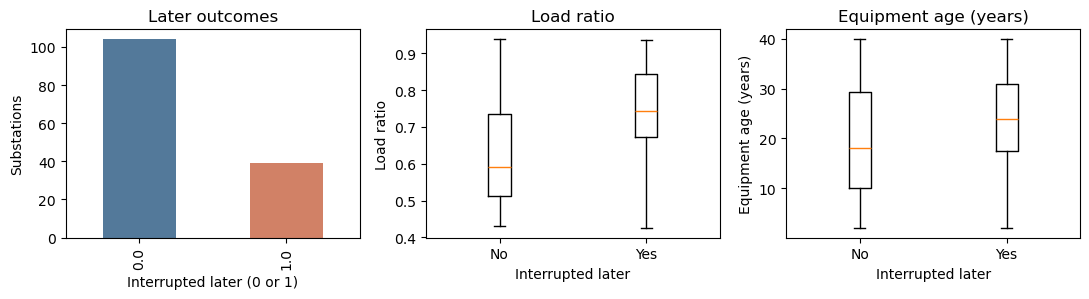

In [ ]:
eligible_eda=substations.loc[substations['initially_interrupted'].eq(0)].copy()
assert eligible_eda['interrupted_later'].notna().all()
counts=eligible_eda['interrupted_later'].value_counts().reindex([0.,1.],fill_value=0)
print('Eligible:',len(eligible_eda),'Later interruptions:',int(counts.loc[1.]))
fig,axes=plt.subplots(1,3,figsize=(11,3.1))
counts.plot.bar(ax=axes[0],color=['#53799a','#d18166'])
axes[0].set(xlabel='Interrupted later (0 or 1)',ylabel='Substations',title='Later outcomes')
for ax,column,label in zip(axes[1:],['load_ratio','equipment_age_years'],['Load ratio','Equipment age (years)']):
    groups=[eligible_eda.loc[eligible_eda['interrupted_later'].eq(k),column] for k in [0,1]]
    ax.boxplot(groups,tick_labels=['No','Yes'])
    ax.set(xlabel='Interrupted later',ylabel=label,title=label)
plt.tight_layout();plt.show()


**Write here:** How many substations are eligible? What overlap do you see in the two original attributes? (Two or three sentences.)

### Answer
143 substations are elegible.

We observe that most substations that were interrupted later have a higher load ratio, with some (roughly those between the first and second quartile, ie. 25% of them) overlapping with part of the third quartile.

On the other hand, the overlap on the equipment age is greater, with almost all of the box of the substations that suffered interruptions overlaping with the upper half of the box of those which were not interrupted.  

## Part 2: undirected physical-link network

Each `power_links.csv` row gives one physical link with no direction or weight. Add every substation as a node. Calculate degree (number of direct links) and local clustering coefficient (what proportion of possible links **among direct neighbours** exists). The few extra local cross-links make clustering vary. Neither feature uses later interruptions.


In [4]:
G=nx.Graph()
G.add_nodes_from(substations['substation_id'])
valid=set(substations['substation_id'])
assert links['substation_a'].isin(valid).all() and links['substation_b'].isin(valid).all()
assert (links['substation_a']!=links['substation_b']).all()
for row in links.itertuples(index=False):
    G.add_edge(row.substation_a, row.substation_b)
assert G.number_of_edges()==len(links)
substations['degree']=[G.degree(i) for i in substations['substation_id']]

clustering=nx.clustering(G)
substations['local_clustering']=[clustering[i] for i in substations['substation_id']]
print('Nodes:',G.number_of_nodes(),'Links:',G.number_of_edges())
print('Degree range:',substations['degree'].min(),substations['degree'].max())
display(substations[['substation_id','degree','local_clustering']].head())


Nodes: 144 Links: 344
Degree range: 2 8


,substation_id,degree,local_clustering
0,S001,2,0.000000
1,S002,3,0.000000
2,S003,4,0.333333
3,S004,4,0.500000
4,S005,3,0.333333


### Visualise and interpret the network

Draw the small network, colouring the initially interrupted node differently from the others, and make one plot comparing the distribution of degree and clustering coefficient. The visualisation uses the **initial** status only. Explain in plain language what a high local clustering value means. The plot is an illustration, not a new model feature.


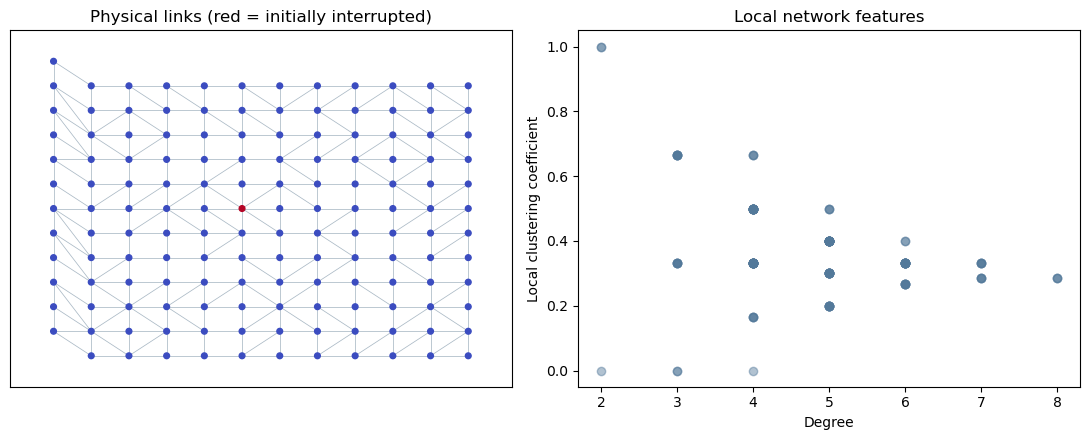

In [5]:
initial=substations.set_index('substation_id')['initially_interrupted']
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
# The numbered IDs encode the synthetic grid's display positions; positions are not predictors.
pos={f'S{i+1:03d}':(i%12,-i//12) for i in range(144)}
nx.draw_networkx(G,pos,ax=axes[0],with_labels=False,node_size=17,
    node_color=[initial.loc[i] for i in G.nodes],cmap='coolwarm',vmin=0,vmax=1,
    edge_color='#aab9c5',width=.55)
axes[0].set_title('Physical links (red = initially interrupted)')
axes[1].scatter(substations['degree'],substations['local_clustering'],alpha=.45,color='#53799a')
axes[1].set(xlabel='Degree',ylabel='Local clustering coefficient',title='Local network features')
plt.tight_layout();plt.show()


**Write here:** What does it mean for a substation's neighbours to be connected to one another? Why is clustering different from degree? (Two sentences.)

### Answer

Mathematically, the connection between neighbors of a substation (measured via the clustering coefficient) represents how well interconected is each substation locally. In this particular context, it represents alternative paths between the different neighboring substations, that could be used if one specific substation was interrupted.

The degree of a node only measures how many neighbors does that one node (substation) have, while clustering measures how many of those neighbors connect with one another.

## Part 3: compare logistic regression fairly

Only initially functioning substations are eligible. Model A uses `load_ratio` and `equipment_age_years`. Model B adds `degree` and `local_clustering`. Use **exactly the same observations and stratified split** for both. Fit scaling within the training pipeline. Compare accuracy, F1 for later interruptions, ROC AUC from probabilities, and both confusion matrices. Do not infer a physical cascade from any result.


,Accuracy,F1,ROC AUC
Original substation features,0.767,0.444,0.828
Substation + network features,0.860,0.750,0.949


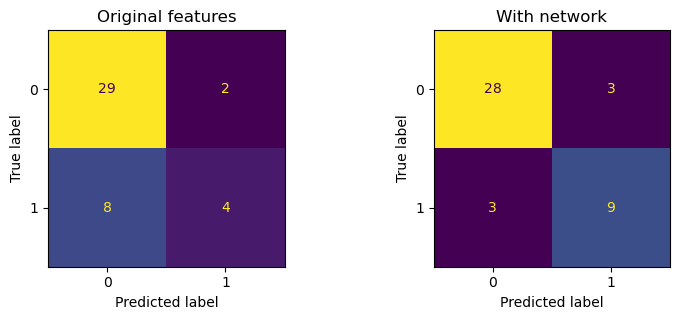

In [ ]:
eligible=substations.loc[substations['initially_interrupted'].eq(0)].set_index('substation_id').copy()
y=eligible['interrupted_later'].astype(int)

train_ids,test_ids=train_test_split(y.index,test_size=0.30,stratify=y,random_state=SEED)
original=['load_ratio','equipment_age_years']

with_network=original+['degree','local_clustering']

def fit_and_score(columns):
    model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
    model.fit(eligible.loc[train_ids,columns],y.loc[train_ids])
    predicted=model.predict(eligible.loc[test_ids,columns])
    probabilities=model.predict_proba(eligible.loc[test_ids,columns])[:,1]
    scores={'Accuracy':accuracy_score(y.loc[test_ids],predicted),
            'F1':f1_score(y.loc[test_ids],predicted,zero_division=0),
            'ROC AUC':roc_auc_score(y.loc[test_ids],probabilities)}
    return scores,predicted
base_scores,base_pred=fit_and_score(original)
network_scores,network_pred=fit_and_score(with_network)
results=pd.DataFrame([base_scores,network_scores],index=['Original substation features','Substation + network features'])
display(results.round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.3))
for ax,pred,title in zip(axes,[base_pred,network_pred],['Original features','With network']):
    ConfusionMatrixDisplay.from_predictions(y.loc[test_ids],pred,ax=ax,labels=[0,1],colorbar=False)
    ax.set_title(title)
plt.tight_layout();plt.show()


### Final interpretation and portfolio summary

**Did adding the network features help predict later interruptions on this test set?** 

Adding network features significantly improved model performance: the original model has a F1 score of 0.444, which improved to 0.750 with network characteristics. The ROC AUC also improved after the inclusion of network features (0.828 vs 0.949), giving us a greater confidence on the predictions. 

Looking at the confusion matrices, the original model commits 10 mistakes (8 of them false negatives). Adding network features: the number of connections between the substations (degree), and how well interconnected are those neighboring stations (local clustering), the number of wrong labels diminished to 6 (3 and 3), a clear improvement in precision and recall. 

Ethically, prioritizing the repairs suggested by the model carries some risks: false negatives would leave some communities exposed to sudden power outages, while false positives would misuse valuable resources. Therefore, these predictions should only be used as supporting material, and the final decision should always be reviewed by engineers, regulatory bodies, and the community.